# EDA: недельный прогноз конфликтных записей для Израиля

Цель исследования — проверить качество данных, понять поведение ряда и выбрать признаки для первого варианта модели.

## 1. Читаем данные

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = pd.read_csv(
    "../data/processed/israel_weekly_merged.csv",
    parse_dates=["week_start", "week_end", "acled_week_start"],
)

data = data.sort_values("week_start").reset_index(drop=True)

data.info()
display(data.head(2))

<class 'pandas.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   country                            157 non-null    str           
 1   country_code                       157 non-null    str           
 2   week_start                         157 non-null    datetime64[us]
 3   week_end                           157 non-null    datetime64[us]
 4   iso_week                           157 non-null    str           
 5   conflict_count_week                157 non-null    int64         
 6   assault_count_week                 157 non-null    int64         
 7   fight_count_week                   157 non-null    int64         
 8   total_events_country               157 non-null    int64         
 9   conflict_share                     157 non-null    float64       
 10  avg_tone                           157 non-null  

,country,country_code,week_start,week_end,iso_week,conflict_count_week,assault_count_week,fight_count_week,total_events_country,conflict_share,...,avg_goldstein_all_events,week_of_year,month,days_with_events,has_country_events,data_split,acled_week_start,acled_battles_overlap_estimate,acled_explosions_overlap_estimate,acled_fatalities
0,Israel,IS,2023-10-02,2023-10-08,2023-W40,20671,4291,16380,84185,0.245543,...,-1.602284,40,10,7,True,development,2023-09-23,0.0,2.857143,0
1,Israel,IS,2023-10-09,2023-10-15,2023-W41,57538,13479,44059,299687,0.191994,...,-1.016014,41,10,7,True,development,2023-09-30,0.0,0.000000,0


`week_start` и `week_end` описывают понедельник–воскресенье GDELT. `acled_week_start` сохраняет исходную субботу ACLED. Ключ присоединения ACLED сдвинут на 9 дней: 2 дня до понедельника и дополнительный недельный лаг. Это допущение о доступности, а не измеренная задержка публикации.

## 2 убираю служебные столбцы

In [3]:
data = data.drop(columns=["country", "country_code", "has_country_events"])

dev = data.loc[data["data_split"] == "development"].copy()

dev = dev.drop(columns="data_split")

## 3. основной ряд во времени

**Гипотеза:** недавний уровень ряда отличается от среднего за всю историю.

Строим недельные количества и среднее последних четырёх недель. `rolling(4).mean()` сглаживает кратковременные колебания и помогает увидеть изменение уровня.

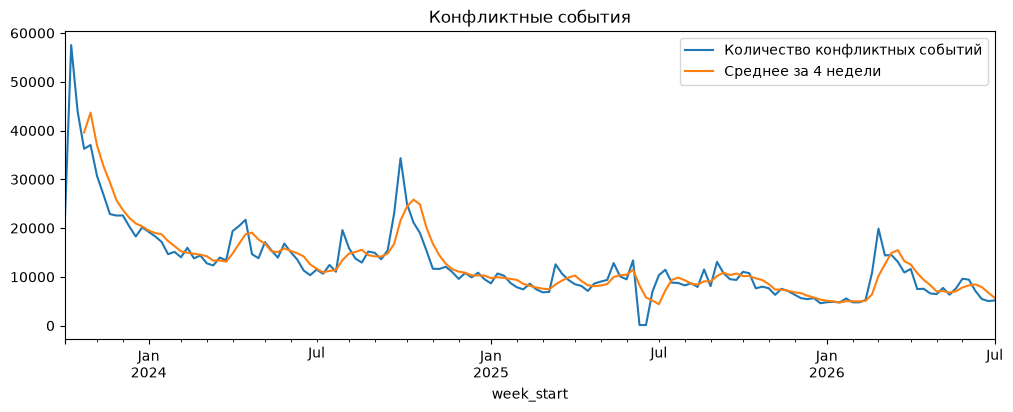

In [4]:
weekly = dev.set_index("week_start")

ax = weekly["conflict_count_week"].plot(
    figsize=(12, 4),
    label="Количество конфликтных событий",
)

weekly["conflict_count_week"].rolling(4).mean().plot(
    ax=ax,
    label="Среднее за 4 недели",
)

ax.legend()
ax.set_title("Конфликтные события")
plt.show()

## 4. распределения

**Гипотеза:** количественные показатели имеют редкие большие значения, которые могут сильно влиять на модель.

Гистограммы показывают, где находится большинство недель и насколько далеко от них лежат большие значения. Они не показывают порядок недель — для этого нужен предыдущий график.

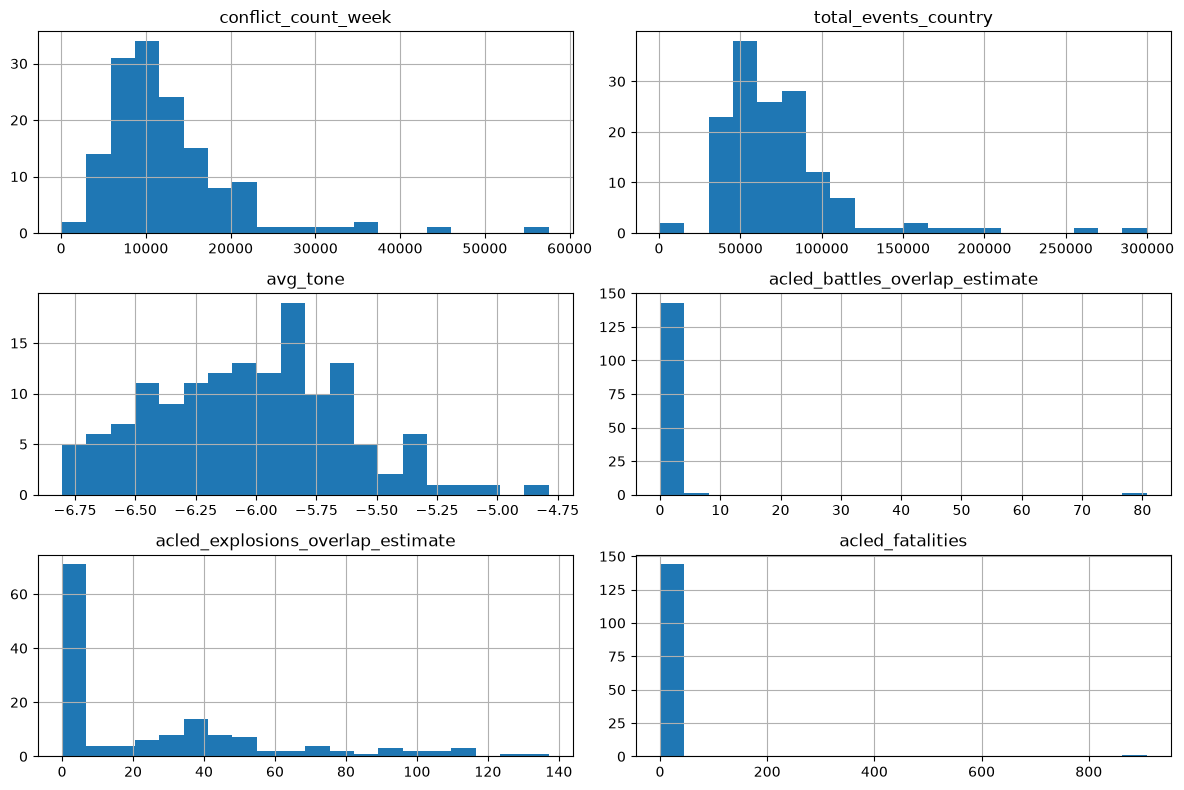

In [5]:
columns = [
    "conflict_count_week",
    "total_events_country",
    "avg_tone",
    "acled_battles_overlap_estimate",
    "acled_explosions_overlap_estimate",
    "acled_fatalities",
]

dev[columns].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

**Вывод:** количества GDELT и показатели ACLED имеют длинный правый хвост. У Battles и Fatalities есть особенно крупное отдельное наблюдение. Его проверим отдельно, а не удалим по форме распределения.

Для неотрицательных количеств можно проверить `log1p`: преобразование уменьшает разницу между обычными и очень большими значениями и сохраняет нули. Его польза для прогноза ещё не измерена. Все признаки не обязаны иметь нормальное распределение; отрицательную тональность обычным `log1p` не преобразуем.

## 5. корреляция между признаками

Смотрим постоянные столбцы и линейную связь между числовыми признаками. Близкие к 1 или −1 коэффициенты указывают на похожую информацию.

In [6]:
numeric = dev.select_dtypes(include="number")

display(numeric.nunique())
display(numeric.corr().round(2))

conflict_count_week                  143
assault_count_week                   144
fight_count_week                     145
total_events_country                 145
conflict_share                       145
avg_tone                             145
avg_goldstein                        145
goldstein_volatility                 145
avg_tone_all_events                  145
avg_goldstein_all_events             145
week_of_year                          52
month                                 12
days_with_events                       1
acled_battles_overlap_estimate         7
acled_explosions_overlap_estimate     62
acled_fatalities                      12
dtype: int64

,conflict_count_week,assault_count_week,fight_count_week,total_events_country,conflict_share,avg_tone,avg_goldstein,goldstein_volatility,avg_tone_all_events,avg_goldstein_all_events,week_of_year,month,days_with_events,acled_battles_overlap_estimate,acled_explosions_overlap_estimate,acled_fatalities
conflict_count_week,1.00,0.97,1.00,0.93,0.47,0.18,-0.16,-0.01,-0.44,-0.38,0.27,0.24,NaN,0.37,0.39,0.34
assault_count_week,0.97,1.00,0.96,0.96,0.35,0.14,0.01,0.16,-0.41,-0.26,0.27,0.24,NaN,0.39,0.31,0.35
fight_count_week,1.00,0.96,1.00,0.92,0.50,0.19,-0.20,-0.06,-0.45,-0.41,0.27,0.24,NaN,0.36,0.41,0.33
total_events_country,0.93,0.96,0.92,1.00,0.15,0.24,0.12,0.23,-0.26,-0.08,0.23,0.20,NaN,0.44,0.25,0.40
conflict_share,0.47,0.35,0.50,0.15,1.00,-0.08,-0.68,-0.53,-0.66,-0.92,0.19,0.20,NaN,0.00,0.53,-0.01
avg_tone,0.18,0.14,0.19,0.24,-0.08,1.00,-0.07,-0.09,0.35,0.11,-0.06,-0.10,NaN,0.05,0.23,0.05
avg_goldstein,-0.16,0.01,-0.20,0.12,-0.68,-0.07,1.00,0.94,0.35,0.65,-0.04,-0.06,NaN,0.03,-0.49,0.02
goldstein_volatility,-0.01,0.16,-0.06,0.23,-0.53,-0.09,0.94,1.00,0.20,0.51,0.02,-0.00,NaN,0.05,-0.40,0.03
avg_tone_all_events,-0.44,-0.41,-0.45,-0.26,-0.66,0.35,0.35,0.20,1.00,0.67,-0.12,-0.12,NaN,-0.06,-0.32,-0.05
avg_goldstein_all_events,-0.38,-0.26,-0.41,-0.08,-0.92,0.11,0.65,0.51,0.67,1.00,-0.14,-0.15,NaN,0.01,-0.47,0.01


**Вывод по предыдущим расчётам:** `days_with_events` постоянен — не используем его в модели. `conflict_count_week` равен сумме Assault и Fight, поэтому для первого варианта оставляем только общее количество.

Корреляция Goldstein и его разброса около 0,94; месяца и номера недели — около 0,93. Для календаря оставляем месяц. Остальные признаки не удаляем только по корреляции: их вклад проверим при обучении.

## 6. логарифмирование признаков с хвостом

Пробуем `log1p` для неотрицательных количеств: он сохраняет нули и сжимает большие значения. Сравниваем новые гистограммы с пунктом 4. Исходный `dev` не меняем.

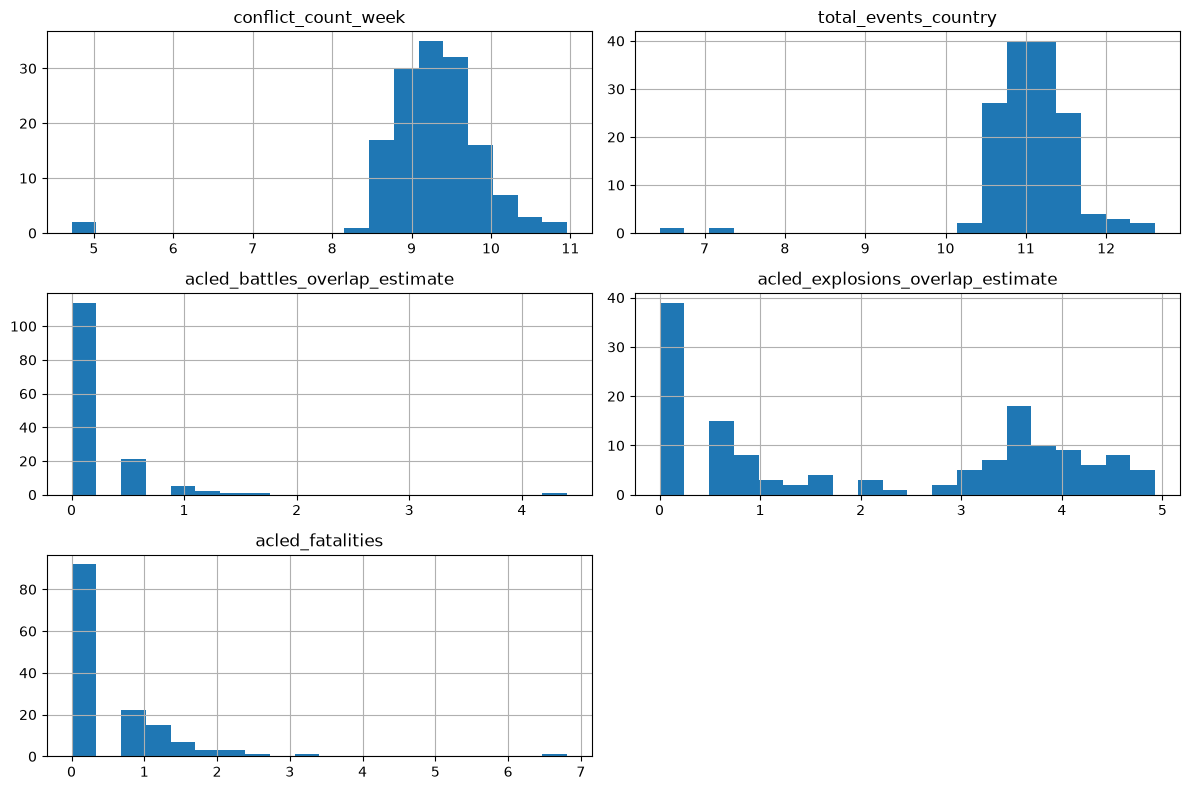

In [7]:
log_columns = [
    "conflict_count_week",
    "total_events_country",
    "acled_battles_overlap_estimate",
    "acled_explosions_overlap_estimate",
    "acled_fatalities",
]

log_data = np.log1p(dev[log_columns])

log_data.hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

**Решение для эксперимента:** проверим исходные количества и вариант с `log1p` на временной валидации. Новую ячейку нужно выполнить; более удобная форма распределения сама по себе не доказывает улучшение прогноза.

Отрицательную тональность не логарифмируем. Цель пока оставляем в исходных единицах — количество записей.

## 7. связь с будущей неделей

Проверяем, какие известные показатели связаны с количеством конфликтных записей на следующей неделе. `shift(-1)` создаёт будущую цель только для этого исследования; в признаки будущее не добавляем.

In [8]:
future = dev.copy()
future["target_h1"] = future["conflict_count_week"].shift(-1)

correlations = (
    future.select_dtypes(include="number")
    .corr(method="spearman")["target_h1"]
    .drop("target_h1")
    .sort_values(ascending=False)
)

display(correlations.round(3))

conflict_count_week                  0.884
fight_count_week                     0.881
assault_count_week                   0.841
total_events_country                 0.793
acled_explosions_overlap_estimate    0.573
conflict_share                       0.500
acled_fatalities                     0.323
acled_battles_overlap_estimate       0.231
avg_tone                             0.203
week_of_year                         0.163
month                                0.122
goldstein_volatility                -0.083
avg_goldstein                       -0.251
avg_goldstein_all_events            -0.435
avg_tone_all_events                 -0.517
days_with_events                       NaN
Name: target_h1, dtype: float64

**Вывод по предыдущим расчётам:** связь с будущей неделей у количества конфликтов — 0,884, у общего объёма GDELT — 0,793, у ACLED Explosions — 0,573. Тональность всех записей связана отрицательно: −0,517.

История основного ряда, объём GDELT и внешний источник — кандидаты для модели. Слабая корреляция не означает, что признак обязательно бесполезен; окончательный выбор сделаем на временной валидации.

## 8. какие признаки будем использовать

Первый набор делаем небольшим и понятным. Прогноз строим после завершённой недели `t` на следующие 1–4 недели.

| Признаки | Зачем нужны |
|---|---|
| `conflict_count_week` | Последнее известное количество — сильный ориентир для будущего |
| Лаги 1, 2, 4, 12 через `shift()` | Активность в предыдущие недели |
| Среднее за 4 недели, разброс за 12, максимум за 8 через `rolling()` | Недавний уровень, нестабильность и всплески |
| Сумма за 12 недель и изменение через `diff()` | Длительная активность и направление изменения |
| `total_events_country`, его изменение через `pct_change()`, `conflict_share` | Общий объём записей и доля конфликтных |
| `avg_tone`, `avg_goldstein`, `goldstein_volatility` | Контекст конфликтных записей |
| `avg_tone_all_events`, `avg_goldstein_all_events` | Контекст всех записей страны |
| Три присоединённых признака ACLED | Дополнительная информация из другого источника |
| `month`, с кодированием перед линейной моделью | Простой календарный признак для проверки |

Количества проверим в исходном и логарифмированном виде как два варианта. Даты, `iso_week`, служебные и постоянные столбцы в модель не подаём. Отдельные Assault и Fight в первом варианте не добавляем.

Текущее значение `conflict_count_week` уже известно: прогнозируем будущую неделю. `shift(1)` означает ещё одну неделю назад. Скользящие окна могут включать завершённую неделю `t`; задержка ACLED уже учтена при объединении.

**Дальше:** сформировать признаки и цели `t+1…t+4`, затем проверить baseline и модели на временной валидации. Масштабирование обучаем только на тренировочной части каждого разбиения. Будущая цель обучающей строки тоже должна оставаться внутри тренировочного периода. Holdout сохраняем для финальной оценки.

Выводы опираются на ранее выполненные расчёты. После упрощения ноутбук нужно выполнить сверху вниз.

## 9. создаём таблицу признаков

`df_features` содержит только числовые входы модели. Считаем признаки на всей отсортированной `data`: это сохраняет историю перед holdout. Используем только текущую завершённую неделю и прошлое.

Для первого варианта оставляем количества в исходном виде. `log1p` сравним отдельным экспериментом после baseline.

In [9]:
base_columns = [
    "conflict_count_week",
    "total_events_country",
    "conflict_share",
    "avg_tone",
    "avg_goldstein",
    "goldstein_volatility",
    "avg_tone_all_events",
    "avg_goldstein_all_events",
    "acled_battles_overlap_estimate",
    "acled_explosions_overlap_estimate",
    "acled_fatalities",
    "month",
]

df_features = data[base_columns].copy()
counts = data["conflict_count_week"]

for lag in [1, 2, 4, 12]:
    df_features[f"conflict_lag_{lag}"] = counts.shift(lag)

# Уровень, разброс и изменения активности.
df_features["conflict_mean_4"] = counts.rolling(4).mean()
df_features["conflict_std_12"] = counts.rolling(12).std()
df_features["conflict_max_8"] = counts.rolling(8).max()
df_features["conflict_sum_12"] = counts.rolling(12).sum()
df_features["conflict_change_1"] = counts.diff()
df_features["news_volume_change"] = data["total_events_country"].pct_change()

df_features["month"] = pd.Categorical(df_features["month"], categories=range(1, 13))
df_features = pd.get_dummies(df_features, columns=["month"], drop_first=True, dtype=int)

df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(df_features.shape)
display(df_features.head(3))

(145, 32)


,conflict_count_week,total_events_country,conflict_share,avg_tone,avg_goldstein,goldstein_volatility,avg_tone_all_events,avg_goldstein_all_events,acled_battles_overlap_estimate,acled_explosions_overlap_estimate,...,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
12,20145,83646,0.240836,-6.327327,-9.826607,0.369429,-5.167454,-1.792939,0.0,41.428571,...,0,0,0,0,0,0,0,0,0,1
13,19232,86812,0.221536,-6.524306,-9.831219,0.365850,-5.234768,-1.557451,0.0,37.142857,...,0,0,0,0,0,0,0,0,0,0
14,18301,96385,0.189874,-6.337967,-9.804164,0.382398,-4.942938,-1.188038,0.0,31.428571,...,0,0,0,0,0,0,0,0,0,0


**Что получили:** текущие показатели, лаги, скользящие статистики, изменения и закодированный месяц. Первые 12 недель не имеют лага 12 и исключаются; нулями их не заполняем.

Даты, метки выборок и будущие ответы не входят в `df_features`. Исходные индексы сохраняем, чтобы признаки, цели и даты соответствовали одним и тем же строкам.

## 10. создаём цели на 1–4 недели вперёд

В `df_targets` храним будущие количества отдельно от признаков. В `target_dates` — даты прогнозируемых недель, чтобы правильно отделить holdout.

In [10]:
df_targets = pd.DataFrame(index=data.index)

for horizon in [1, 2, 3, 4]:
    df_targets[f"target_h{horizon}"] = counts.shift(-horizon)

# join сопоставляет признаки и ответы по исходным индексам.
dataset = df_features.join(df_targets)

# Дата нужна для временного разделения, но не является входом модели.
dataset.insert(
    0,
    "week_start",
    data.loc[dataset.index, "week_start"],
)

dataset.to_csv(
    "../data/processed/israel_model_dataset.csv",
    index=False,
)

display(dataset.head(3))

,week_start,conflict_count_week,total_events_country,conflict_share,avg_tone,avg_goldstein,goldstein_volatility,avg_tone_all_events,avg_goldstein_all_events,acled_battles_overlap_estimate,...,month_7,month_8,month_9,month_10,month_11,month_12,target_h1,target_h2,target_h3,target_h4
12,2023-12-25,20145,83646,0.240836,-6.327327,-9.826607,0.369429,-5.167454,-1.792939,0.0,...,0,0,0,0,0,1,19232.0,18301.0,17176.0,14640.0
13,2024-01-01,19232,86812,0.221536,-6.524306,-9.831219,0.365850,-5.234768,-1.557451,0.0,...,0,0,0,0,0,0,18301.0,17176.0,14640.0,15120.0
14,2024-01-08,18301,96385,0.189874,-6.337967,-9.804164,0.382398,-4.942938,-1.188038,0.0,...,0,0,0,0,0,0,17176.0,14640.0,15120.0,14018.0


**Что получили:** четыре цели для отдельных горизонтов. Последние значения некоторых целей неизвестны и остаются `NaN`. Для обучения они не подходят, но признаки последних завершённых недель можно использовать для будущего прогноза.